# Week 5 Lab Session Worksheet: Statistical Visualisation with Titanic Dataset
This notebook contains activities and exercises for analysing and visualising the [`titanic.csv`](https://web.stanford.edu/class/archive/cs/cs109/cs109.1166/stuff/titanic.csv) dataset using pandas, matplotlib, numpy, and [SciPy](https://scipy.org/).



## Importatnt 

You need to replace `titanic.csv` in the same folder as `Week_5_Lab_Session_Worksheet`

- Remember to handle missing values appropriately
- Consider the scale of your variables when choosing visualisations
- Document your findings and interpretations
- Pay attention to outliers and their potential impact
- Use appropriate statistical tests for your analyses.
- Visit [Statistical functions in `scipy.stats`](https://docs.scipy.org/doc/scipy/reference/stats.html)

In [1]:
# First, let's import the necessary libraries and load the data.
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Read the dataset
df = pd.read_csv('titanic.csv')

# Set figure size and basic plotting parameters
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['axes.grid'] = True

In [ ]:
#or you can load the dataset using seaborn
#load Titanic Dataset
#titanic = sns.load_dataset('titanic');
#titanic.info();

**Exercise 1:**  Exploring Interval and Ratio Scale Data

**Objective:** Identify and visualise different types of numerical data in the Titanic dataset.

**Tasks:**
1. Identify interval and ratio scale variables in the dataset
2. Create appropriate visualisations for each type
3. Calculate relevant summary statistics

              age        fare       sibsp       parch
count  714.000000  891.000000  891.000000  891.000000
mean    29.699118   32.204208    0.523008    0.381594
std     14.526497   49.693429    1.102743    0.806057
min      0.420000    0.000000    0.000000    0.000000
25%     20.125000    7.910400    0.000000    0.000000
50%     28.000000   14.454200    0.000000    0.000000
75%     38.000000   31.000000    1.000000    0.000000
max     80.000000  512.329200    8.000000    6.000000


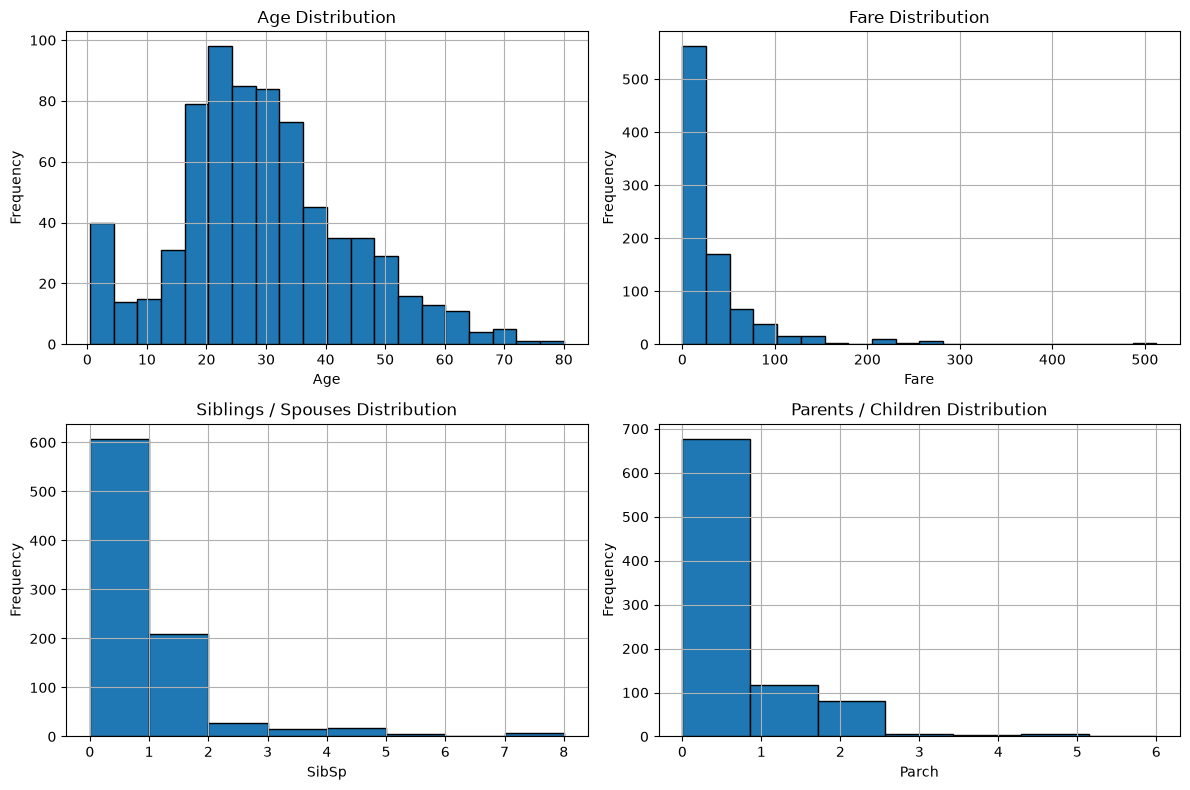

In [3]:
# Sart your solution 
# print(df.head())
# print(df.info())

# Ratio scale variables in this dataset
ratio_columns = ['age', 'fare', 'sibsp', 'parch']

# Show summary statistics
print(df[ratio_columns].describe())


# Create plots for the numerical variables
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Age distribution
axes[0, 0].hist(
    df['age'].dropna(),
    bins=20,
    edgecolor='black'
)
axes[0, 0].set_title('Age Distribution')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Frequency')


# Fare distribution
axes[0, 1].hist(
    df['fare'].dropna(),
    bins=20,
    edgecolor='black'
)
axes[0, 1].set_title('Fare Distribution')
axes[0, 1].set_xlabel('Fare')
axes[0, 1].set_ylabel('Frequency')


# Number of siblings/spouses
axes[1, 0].hist(
    df['sibsp'],
    bins=8,
    edgecolor='black'
)
axes[1, 0].set_title('Siblings / Spouses Distribution')
axes[1, 0].set_xlabel('SibSp')
axes[1, 0].set_ylabel('Frequency')


# Number of parents/children
axes[1, 1].hist(
    df['parch'],
    bins=7,
    edgecolor='black'
)
axes[1, 1].set_title('Parents / Children Distribution')
axes[1, 1].set_xlabel('Parch')
axes[1, 1].set_ylabel('Frequency')


plt.tight_layout()

# Save the figure
plt.savefig(
    'ratio_scale_variables.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

**Exercise 2:** Measures of Central Tendency and Spread

**Objective:** Analyse the distribution of passenger ages across different passenger classes.

**Tasks:**
1. Calculate measures of central tendency for age by passenger class
2. Create box plots to visualise the spread
3. Identify potential outliers

             mean  median        std   min   max
pclass                                          
1       38.233441    37.0  14.802856  0.92  80.0
2       29.877630    29.0  14.001077  0.67  70.0
3       25.140620    24.0  12.495398  0.42  74.0


<Figure size 1000x600 with 0 Axes>

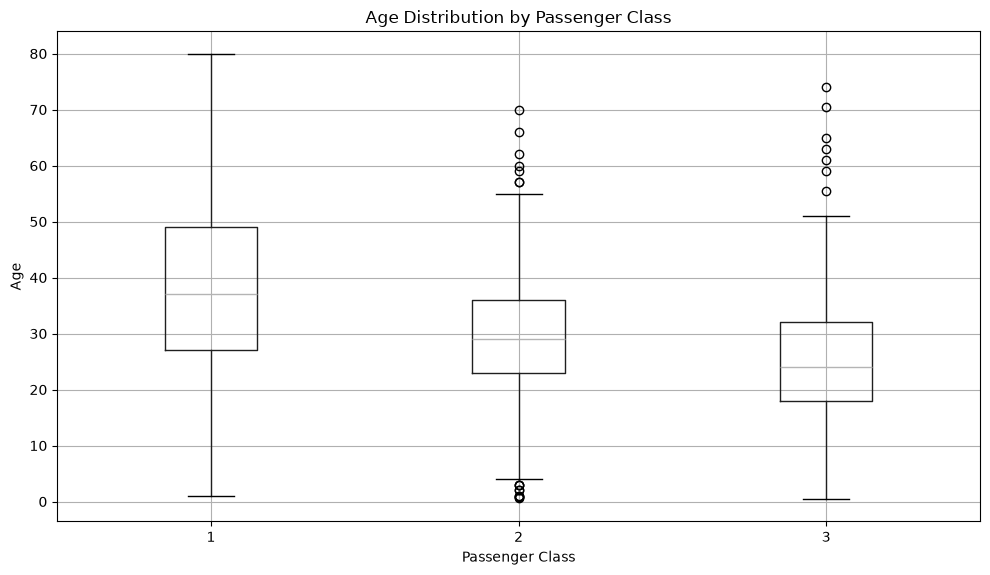

Passenger class 1 - number of outliers: 0
Passenger class 2 - number of outliers: 17
Passenger class 3 - number of outliers: 7


In [4]:
# Sart your solution 

# Remove rows where age is missing
age_data = df.dropna(subset=['age'])

# Calculate age statistics for each passenger class
age_stats = age_data.groupby('pclass')['age'].agg(
    ['mean', 'median', 'std', 'min', 'max']
)

print(age_stats)


# Create a box plot for age by passenger class
plt.figure(figsize=(10, 6))

age_data.boxplot(
    column='age',
    by='pclass'
)

plt.title('Age Distribution by Passenger Class')
plt.suptitle('')
plt.xlabel('Passenger Class')
plt.ylabel('Age')

plt.tight_layout()

# Save the chart
plt.savefig(
    'age_by_passenger_class.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# Find possible outliers using the IQR method
for passenger_class in [1, 2, 3]:

    class_ages = age_data[
        age_data['pclass'] == passenger_class
    ]['age']

    q1 = class_ages.quantile(0.25)
    q3 = class_ages.quantile(0.75)

    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outliers = class_ages[
        (class_ages < lower_limit) |
        (class_ages > upper_limit)
    ]

    print(
        'Passenger class',
        passenger_class,
        '- number of outliers:',
        len(outliers)
    )

**Exercise 3:** Distribution Shape Analysis

**Objective:** Examine the shape of fare distributions and identify skewness patterns.

**Tasks:**
1. Create visualisations to show fare distribution shape
2. Calculate skewness and kurtosis
3. Compare fare distributions across survival status

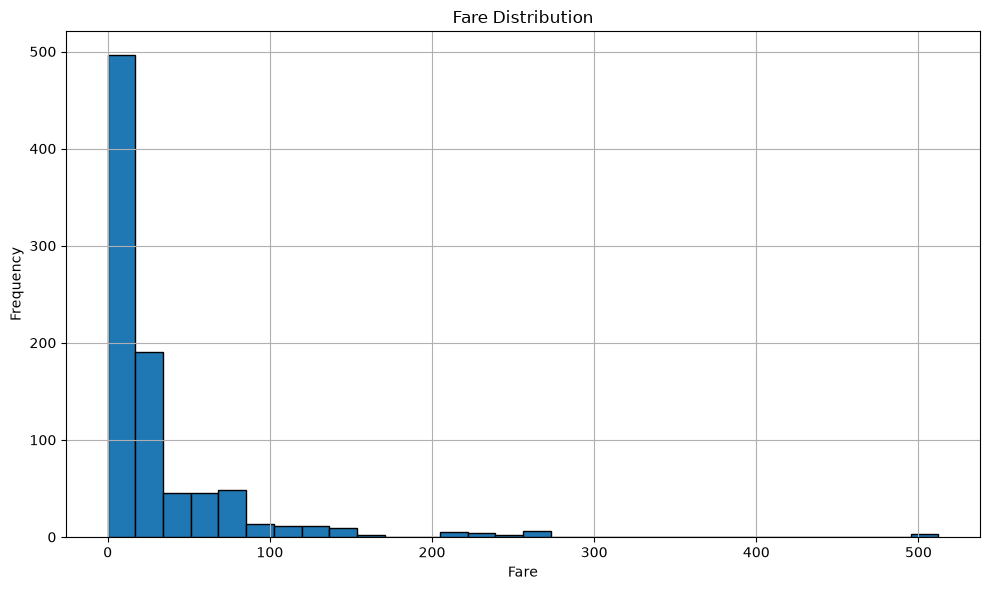

Fare skewness: 4.7792532923723545
Fare kurtosis: 33.20428925264474


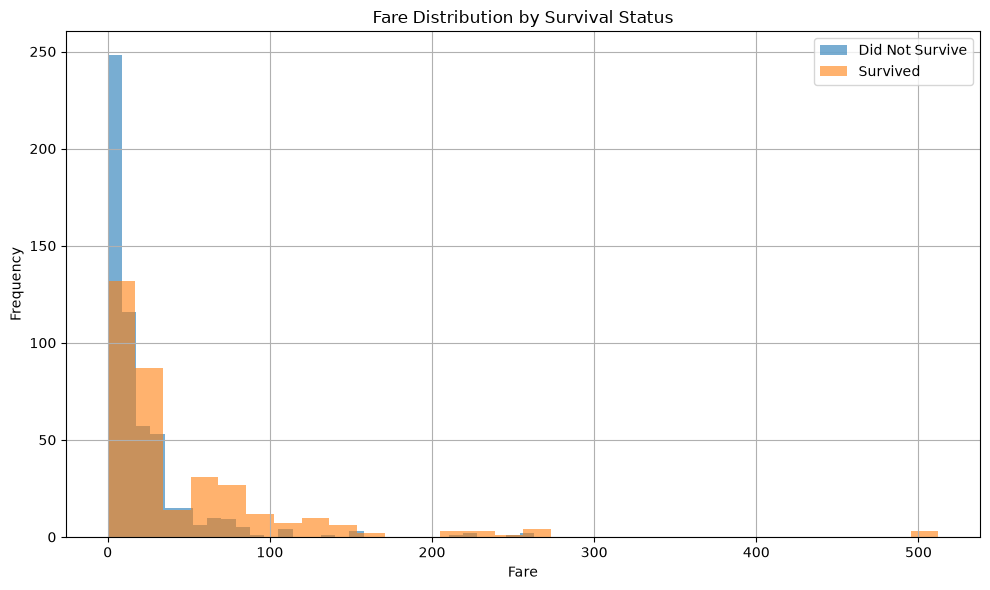

In [5]:
# Sart your solution 

# Remove missing fare values if there are any
fare_data = df['fare'].dropna()

# Show the overall fare distribution
plt.figure(figsize=(10, 6))

plt.hist(
    fare_data,
    bins=30,
    edgecolor='black'
)

plt.title('Fare Distribution')
plt.xlabel('Fare')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


# Calculate skewness and kurtosis
fare_skewness = stats.skew(fare_data)
fare_kurtosis = stats.kurtosis(fare_data)

print('Fare skewness:', fare_skewness)
print('Fare kurtosis:', fare_kurtosis)


# Compare fare distribution by survival status
survived_fares = df[df['survived'] == 1]['fare'].dropna()
not_survived_fares = df[df['survived'] == 0]['fare'].dropna()

plt.figure(figsize=(10, 6))

plt.hist(
    not_survived_fares,
    bins=30,
    alpha=0.6,
    label='Did Not Survive'
)

plt.hist(
    survived_fares,
    bins=30,
    alpha=0.6,
    label='Survived'
)

plt.title('Fare Distribution by Survival Status')
plt.xlabel('Fare')
plt.ylabel('Frequency')

plt.legend()
plt.tight_layout()

plt.show()

**Exercise 4:** Correlation Analysis

**Objective:** Investigate relationships between numerical variables.

**Tasks:**
1. Calculate different correlation coefficients
2. Create scatter plots
3. Interpret the relationships

Pearson Correlation:
            age      fare     sibsp     parch
age    1.000000  0.096067 -0.308247 -0.189119
fare   0.096067  1.000000  0.138329  0.205119
sibsp -0.308247  0.138329  1.000000  0.383820
parch -0.189119  0.205119  0.383820  1.000000

Spearman Correlation:
            age      fare     sibsp     parch
age    1.000000  0.135051 -0.182061 -0.254212
fare   0.135051  1.000000  0.422994  0.407150
sibsp -0.182061  0.422994  1.000000  0.426955
parch -0.254212  0.407150  0.426955  1.000000


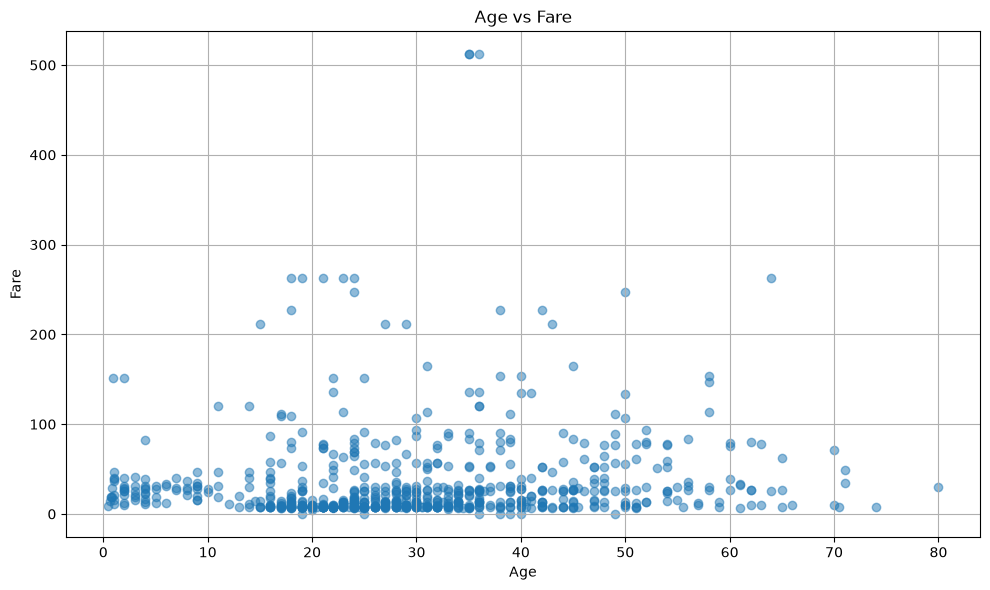

In [6]:
# Sart your solution 


# Keep only the numerical columns we want to compare
correlation_data = df[
    ['age', 'fare', 'sibsp', 'parch']
].dropna()

# Calculate Pearson correlation
pearson_corr = correlation_data.corr(method='pearson')

# Calculate Spearman correlation
spearman_corr = correlation_data.corr(method='spearman')

print('Pearson Correlation:')
print(pearson_corr)

print('\nSpearman Correlation:')
print(spearman_corr)


# Create scatter plot for age and fare
plt.figure(figsize=(10, 6))

plt.scatter(
    correlation_data['age'],
    correlation_data['fare'],
    alpha=0.5
)

plt.title('Age vs Fare')
plt.xlabel('Age')
plt.ylabel('Fare')

plt.tight_layout()
plt.show()

**Exercise 5:** Simple Linear Regression

**Objective:** Model the relationship between age and fare.

**Tasks:**
1. Perform simple linear regression
2. Create scatter plot with regression line
3. Analyse the model assumptions


Slope: 0.34996368174402315
Intercept: 24.30090144928865
R-squared: 0.009228809267447525
P-value: 0.010216277504447034


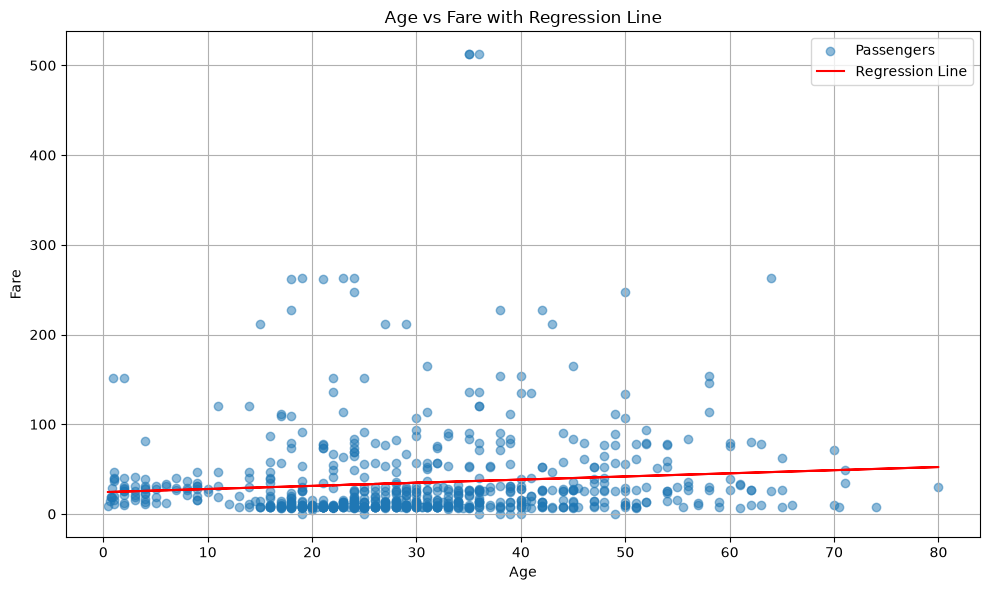

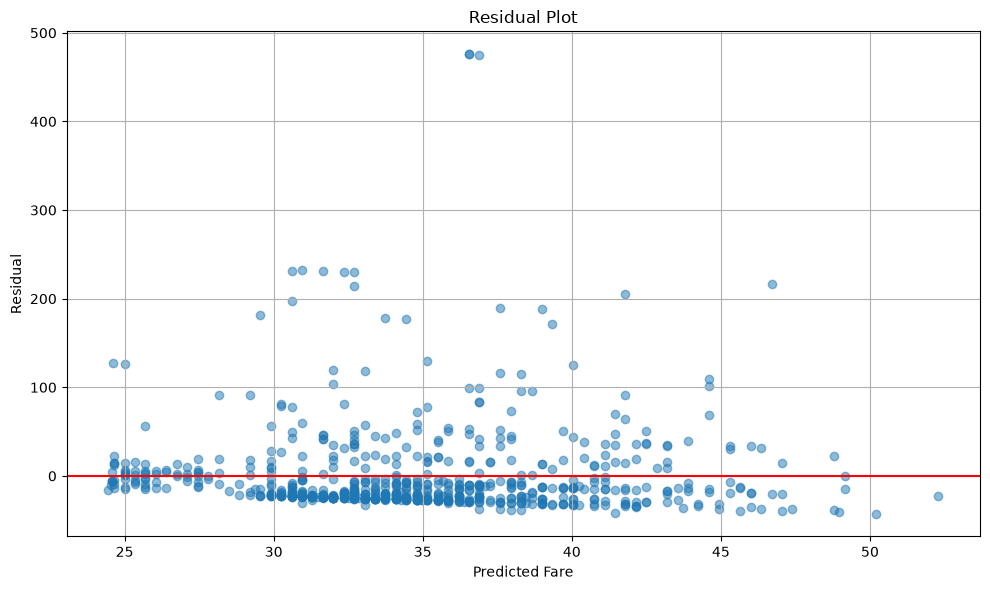

In [7]:
# Sart your solution 



# Keep only rows where age and fare are available
regression_data = df[['age', 'fare']].dropna()

x = regression_data['age']
y = regression_data['fare']

# Run the linear regression
result = stats.linregress(x, y)

slope = result.slope
intercept = result.intercept
r_value = result.rvalue
p_value = result.pvalue

print('Slope:', slope)
print('Intercept:', intercept)
print('R-squared:', r_value ** 2)
print('P-value:', p_value)


# Calculate the predicted fare values
predicted_fare = intercept + slope * x


# Create scatter plot with regression line
plt.figure(figsize=(10, 6))

plt.scatter(
    x,
    y,
    alpha=0.5,
    label='Passengers'
)

plt.plot(
    x,
    predicted_fare,
    color='red',
    label='Regression Line'
)

plt.title('Age vs Fare with Regression Line')
plt.xlabel('Age')
plt.ylabel('Fare')

plt.legend()
plt.tight_layout()

plt.show()


# Calculate residuals
residuals = y - predicted_fare

# Plot residuals to check the model
plt.figure(figsize=(10, 6))

plt.scatter(
    predicted_fare,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color='red'
)

plt.title('Residual Plot')
plt.xlabel('Predicted Fare')
plt.ylabel('Residual')

plt.tight_layout()

plt.show()

## Bonus Challenges:

1. Investigate survival rates across different age groups
2. Compare fare distributions between male and female passengers
3. Create a multivariate analysis of survival probability based on age and fare
4. Analyse the effect of family size on survival rates
5. Create a comprehensive dashboard showing key insights from the dataset


In [ ]:
# Sart your solution 